# Optimizing Marketing Spending using Bayesian Marketing Mix Modeling

Can marketing spend be reallocated or reduced while maintaining projected GMV?

This self-project uses **156 weeks of synthetic data**, measured in illustrative currency units (CU).
I estimate channel carryover and diminishing returns, inspect the Bayesian model, and compare two
SLSQP budget scenarios. The results demonstrate a method, not a real company's marketing recommendation.

## 1. Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import pytensor
import pytensor.tensor as pt
import arviz as az
from scipy.optimize import minimize
from IPython.display import display, Markdown

random_seed = 42
# Numba compiles the sampler's math; a separate C++ toolchain is not needed.
pytensor.config.cxx = ''
output_folder = Path('outputs')
output_folder.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.options.display.float_format = '{:,.2f}'.format

## 2. Load and inspect data

The CSV was generated once with seed 42. Channel spending varies through independent campaign flights
and weekly fluctuations. GMV includes delayed marketing effects, saturation, trend, annual seasonality,
price, promotions, holidays and noise. No optimized budget was used to generate it.

The exact generation recipe is included below as optional documentation; Run All only loads the CSV.

<details>
<summary>Optional: reproduce the synthetic CSV</summary>

Run this separately from the repository root with NumPy and pandas imported. It overwrites the CSV.

```python
rng = np.random.default_rng(42)
weeks = 156
week = np.arange(weeks)
dates = pd.date_range('2023-01-02', periods=weeks, freq='W-MON')
channel_columns = ['paid_search_spend', 'social_spend', 'display_spend',
                   'video_spend', 'affiliate_spend']
typical_spend = np.array([24000, 19000, 15000, 17000, 9000])
spend = np.zeros((weeks, 5))
for j in range(5):
    campaign = np.zeros(weeks)
    for t in range(1, weeks):
        campaign[t] = 0.35 * campaign[t - 1] + rng.normal(0, 0.43)
    flight = rng.choice([0.45, 0.8, 1.2, 1.6], size=39).repeat(4)
    spend[:, j] = typical_spend[j] * np.exp(campaign) * flight
spend = np.round(spend, 2)
price_index = np.round(1 + 0.025 * np.sin(week / 9) + rng.normal(0, 0.025, weeks), 4)
promotion = rng.binomial(1, 0.23, weeks)
holiday = np.isin(dates.isocalendar().week.to_numpy(), [1, 46, 47, 51, 52]).astype(int)

# Eight normalized lag weights keep adstock in weekly-spend units.
# Zero prehistory represents a new campaign program at the start of the series.
decay = np.array([0.25, 0.45, 0.30, 0.65, 0.20])
half_saturation = typical_spend * np.array([1.1, 0.7, 0.45, 0.85, 1.25])
maximum_contribution = np.array([125000, 90000, 35000, 70000, 95000])
channel_gmv = np.zeros_like(spend)
for j in range(5):
    weights = decay[j] ** np.arange(8)
    weights = weights / weights.sum()
    adstocked_spend = np.convolve(spend[:, j], weights)[:weeks]
    channel_gmv[:, j] = maximum_contribution[j] * adstocked_spend / (half_saturation[j] + adstocked_spend)
baseline = (115000 + 160 * week + 15000 * np.sin(2 * np.pi * week / 52)
            + 7000 * np.cos(2 * np.pi * week / 52)
            - 210000 * (price_index - 1) + 23000 * promotion + 17000 * holiday)
gmv = baseline + channel_gmv.sum(axis=1) + rng.normal(0, 6500, weeks)
marketing_data = pd.DataFrame(spend, columns=channel_columns)
marketing_data.insert(0, 'date', dates)
marketing_data['price_index'] = price_index
marketing_data['promotion'] = promotion
marketing_data['holiday'] = holiday
marketing_data['gmv'] = np.round(gmv, 2)
marketing_data.to_csv('data/marketing_data.csv', index=False)
```

</details>

In [2]:
marketing_data = pd.read_csv('data/marketing_data.csv', parse_dates=['date'])
marketing_data.head()

,date,paid_search_spend,social_spend,display_spend,video_spend,affiliate_spend,price_index,promotion,holiday,gmv
0,2023-01-02,"28,800.00","30,400.00","18,000.00","27,200.00","10,800.00",1.01,0,1,"341,904.05"
1,2023-01-09,"32,832.00","32,741.89","9,118.33","25,051.63","7,714.54",0.98,0,0,"345,533.52"
2,2023-01-16,"19,279.50","61,523.94","26,762.45","48,330.50","3,539.69",1.02,0,0,"350,620.19"
3,2023-01-23,"34,556.75","41,678.41","24,229.84","27,498.26","4,829.55",1.01,0,0,"363,468.56"
4,2023-01-30,"45,997.99","16,130.63","10,778.98","25,522.40","7,330.43",0.96,1,0,"394,378.82"


In [3]:
print('Shape:', marketing_data.shape)
marketing_data.info()
display(marketing_data.describe())
display(marketing_data.isna().sum().rename('missing_values'))
print('Date range:', marketing_data['date'].min(), 'to', marketing_data['date'].max())

assert not marketing_data.isna().any().any()
assert not marketing_data['date'].duplicated().any()
marketing_data = marketing_data.sort_values('date').reset_index(drop=True)
assert marketing_data['date'].diff().dropna().eq(pd.Timedelta(days=7)).all()
assert (marketing_data['gmv'] > 0).all()
assert marketing_data[['promotion', 'holiday']].isin([0, 1]).all().all()

Shape: (156, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               156 non-null    datetime64[ns]
 1   paid_search_spend  156 non-null    float64       
 2   social_spend       156 non-null    float64       
 3   display_spend      156 non-null    float64       
 4   video_spend        156 non-null    float64       
 5   affiliate_spend    156 non-null    float64       
 6   price_index        156 non-null    float64       
 7   promotion          156 non-null    int64         
 8   holiday            156 non-null    int64         
 9   gmv                156 non-null    float64       
dtypes: datetime64[ns](1), float64(7), int64(2)
memory usage: 12.3 KB


,date,paid_search_spend,social_spend,display_spend,video_spend,affiliate_spend,price_index,promotion,holiday,gmv
count,156,156.00,156.00,156.00,156.00,156.00,156.00,156.00,156.00,156.00
mean,2024-06-27 12:00:00,"26,288.10","23,127.71","18,155.96","18,870.07","8,989.81",1.00,0.26,0.10,"347,138.58"
min,2023-01-02 00:00:00,"4,071.39","3,396.75","2,098.21","3,747.24","1,280.31",0.92,0.00,0.00,"243,682.67"
25%,2023-09-30 06:00:00,"13,813.39","12,799.50","9,260.56","11,105.68","4,473.39",0.98,0.00,0.00,"323,372.89"
50%,2024-06-27 12:00:00,"21,316.28","19,873.12","14,807.93","16,373.77","7,028.31",1.00,0.00,0.00,"350,789.42"
75%,2025-03-25 18:00:00,"34,717.15","30,259.36","24,558.24","23,203.40","10,512.13",1.02,1.00,0.00,"371,906.82"
max,2025-12-22 00:00:00,"106,126.79","79,161.84","76,074.57","71,124.19","35,988.81",1.07,1.00,1.00,"441,996.70"
std,NaN,"16,824.19","14,851.23","11,856.92","10,760.85","6,880.15",0.03,0.44,0.30,"33,926.38"


date                 0
paid_search_spend    0
social_spend         0
display_spend        0
video_spend          0
affiliate_spend      0
price_index          0
promotion            0
holiday              0
gmv                  0
Name: missing_values, dtype: int64

Date range: 2023-01-02 00:00:00 to 2025-12-22 00:00:00


## 3. Marketing channels and basic EDA

paid_search_spend   4,100,944.26
social_spend        3,607,922.55
display_spend       2,832,329.21
video_spend         2,943,731.45
affiliate_spend     1,402,410.12
Name: total_spend, dtype: float64

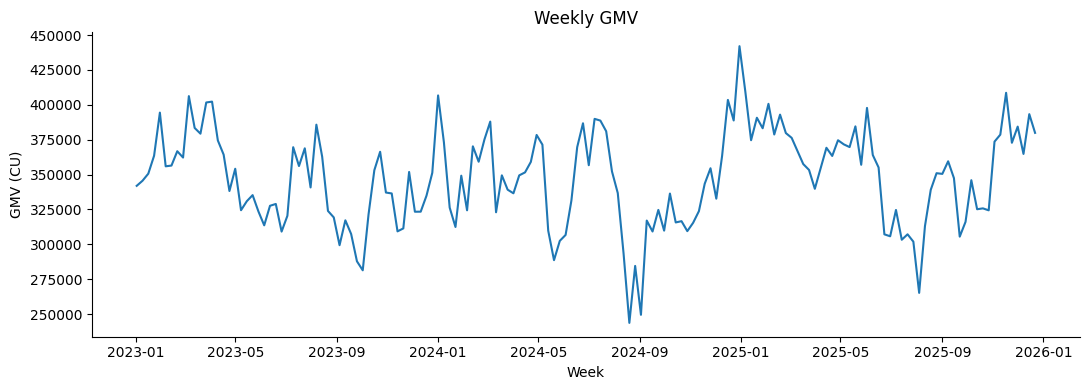

In [4]:
channel_columns = ['paid_search_spend', 'social_spend', 'display_spend',
                   'video_spend', 'affiliate_spend']
channel_names = ['Paid search', 'Social', 'Display', 'Video', 'Affiliate']
control_columns = ['price_index', 'promotion', 'holiday']
assert (marketing_data[channel_columns] >= 0).all().all()
display(marketing_data[channel_columns].sum().rename('total_spend'))

plt.plot(marketing_data['date'], marketing_data['gmv'], color='tab:blue')
plt.title('Weekly GMV')
plt.xlabel('Week')
plt.ylabel('GMV (CU)')
plt.tight_layout()
plt.show()

GMV varies week to week, with a gradual increase across the series. Spend alone will not explain this pattern, so the model also includes trend and business controls.

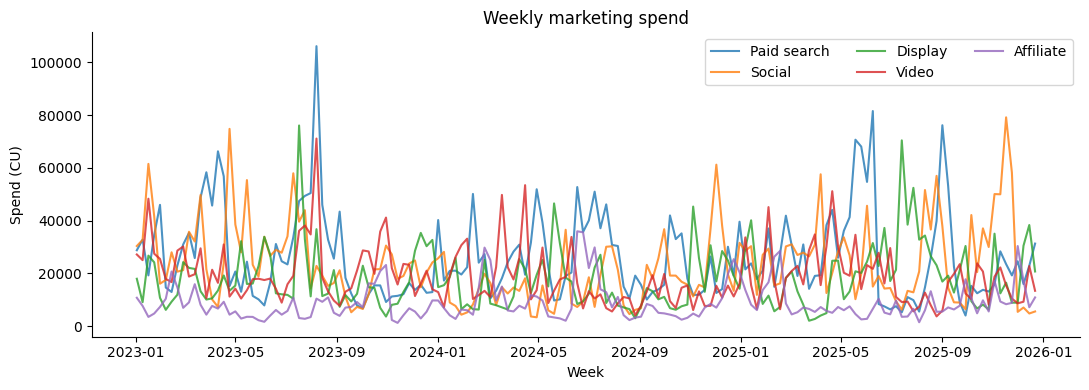

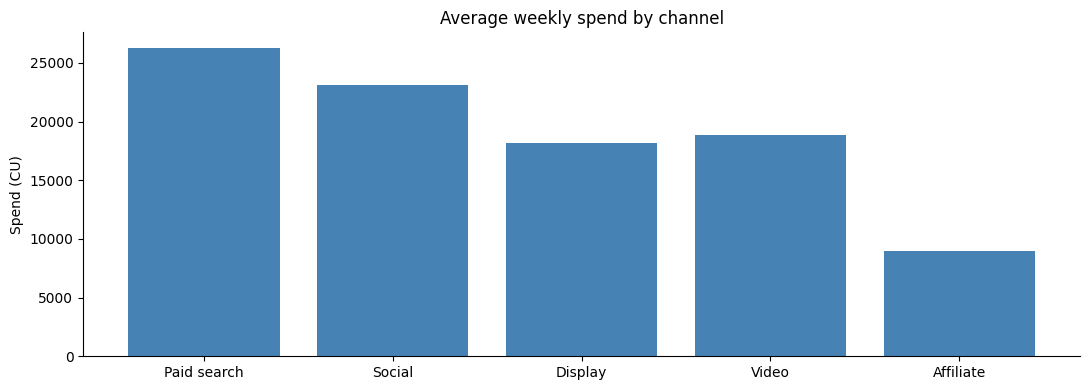

In [5]:
for channel, name in zip(channel_columns, channel_names):
    plt.plot(marketing_data['date'], marketing_data[channel], label=name, alpha=0.8)
plt.title('Weekly marketing spend')
plt.xlabel('Week')
plt.ylabel('Spend (CU)')
plt.legend(ncol=3)
plt.tight_layout()
plt.show()

plt.bar(channel_names, marketing_data[channel_columns].mean(), color='steelblue')
plt.title('Average weekly spend by channel')
plt.ylabel('Spend (CU)')
plt.tight_layout()
plt.show()

The channels have different budgets and campaign patterns. A larger budget does not necessarily mean a higher return; the model needs to separate spend levels from response efficiency.

## 4. Scale the data

Spend is divided by each channel's mean and GMV by its overall mean. Controls are centered and divided
by their standard deviations. These values are kept for converting predictions back to CU.
The trend is centered, and one sine/cosine pair represents a 52-week seasonal cycle.

In [6]:
spend_scale = marketing_data[channel_columns].mean().to_numpy()
gmv_scale = marketing_data['gmv'].mean()
scaled_spend = marketing_data[channel_columns].to_numpy() / spend_scale
scaled_gmv = marketing_data['gmv'].to_numpy() / gmv_scale

week_number = np.arange(len(marketing_data))
controls = marketing_data[control_columns].copy()
controls['trend'] = week_number
controls['season_sin'] = np.sin(2 * np.pi * week_number / 52)
controls['season_cos'] = np.cos(2 * np.pi * week_number / 52)
control_mean = controls.mean()
control_scale = controls.std(ddof=0)
scaled_controls = ((controls - control_mean) / control_scale).to_numpy()
display(pd.Series(spend_scale, index=channel_names, name='spend_scale'))
print(f'GMV scale: {gmv_scale:,.2f} CU')

Paid search   26,288.10
Social        23,127.71
Display       18,155.96
Video         18,870.07
Affiliate      8,989.81
Name: spend_scale, dtype: float64

GMV scale: 347,138.58 CU


## 5. Adstock and saturation

Marketing can affect customers after the week in which it is purchased. Geometric adstock gives past
spend a weight of `decay ** lag`, using the current week and seven previous weeks. I normalize the weights
to keep the transformed spend in weekly-spend units. Prehistory is zero, matching the synthetic campaign start.

The Hill curve is `x / (half_saturation + x)`. I fix its exponent at 1: the response is concave and has
diminishing marginal returns everywhere. Each channel estimates its own half-saturation point and maximum
contribution. Estimating another shape parameter from only three years would add avoidable ambiguity.

In [7]:
max_lag = 8

def geometric_adstock(spend, decay, max_lag=8):
    weights = decay ** np.arange(max_lag)
    weights = weights / weights.sum()
    return np.convolve(spend, weights, mode='full')[:len(spend)]

def hill_saturation(adstocked_spend, half_saturation):
    return adstocked_spend / (half_saturation + adstocked_spend)

# This fixed lag array lets PyTensor estimate decay without a recursive scan.
lagged_spend = np.zeros((len(marketing_data), max_lag, len(channel_columns)))
for lag in range(max_lag):
    if lag == 0:
        lagged_spend[:, lag, :] = scaled_spend
    else:
        lagged_spend[lag:, lag, :] = scaled_spend[:-lag]

test_decay = 0.4
test_weights = test_decay ** np.arange(max_lag)
test_adstock = (lagged_spend[:, :, 0] * test_weights).sum(axis=1) / test_weights.sum()
assert np.allclose(test_adstock, geometric_adstock(scaled_spend[:, 0], test_decay))
assert hill_saturation(0, 1) == 0

## 6. Bayesian MMM

The expected scaled GMV is an intercept plus centered controls and positive channel contributions.
The intercept prior allows substantial non-marketing demand. HalfNormal marketing priors prevent negative
channel contributions, while Normal control priors allow either direction. Beta(2, 3) regularizes carryover
away from extreme values. A LogNormal half-saturation prior concentrates on the observed spend range
without fixing a channel's efficiency. Noise has a HalfNormal prior.

These priors help separate baseline from media effects, which can otherwise trade off. They are modeling
assumptions, not facts learned from the data. I use the same priors across channels, without giving the
model the synthetic generating parameters.

In [8]:
coords = {'week': marketing_data['date'].to_numpy(), 'channel': channel_names,
          'control': controls.columns.to_list()}

with pm.Model(coords=coords) as mmm:
    intercept = pm.Normal('intercept', mu=0.5, sigma=0.3)
    channel_coefficient = pm.HalfNormal('channel_coefficient', sigma=0.4, dims='channel')
    adstock_decay = pm.Beta('adstock_decay', alpha=2, beta=3, dims='channel')
    half_saturation = pm.LogNormal('half_saturation', mu=np.log(0.8), sigma=0.5, dims='channel')
    control_coefficient = pm.Normal('control_coefficient', mu=0, sigma=0.15, dims='control')
    sigma = pm.HalfNormal('sigma', sigma=0.1)

    weights = adstock_decay[None, :] ** np.arange(max_lag)[:, None]
    weights = weights / pt.sum(weights, axis=0)
    adstocked_spend = pt.sum(pt.as_tensor_variable(lagged_spend) * weights[None, :, :], axis=1)
    saturated_spend = hill_saturation(adstocked_spend, half_saturation)
    media_contribution = pm.Deterministic('media_contribution',
                                         saturated_spend * channel_coefficient,
                                         dims=('week', 'channel'))
    expected_gmv = pm.Deterministic('expected_gmv',
        intercept + pt.dot(scaled_controls, control_coefficient) + media_contribution.sum(axis=1),
        dims='week')
    observed_gmv = pm.Normal('observed_gmv', mu=expected_gmv, sigma=sigma,
                            observed=scaled_gmv, dims='week')

In [9]:
print('Fitting Bayesian MMM...')
with mmm:
    idata = pm.sample(draws=1000, tune=1000, chains=2, cores=1,
                      target_accept=0.95, random_seed=random_seed,
                      compile_kwargs={'mode': 'NUMBA'})

Fitting Bayesian MMM...


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (2 chains in 1 job)


NUTS: [intercept, channel_coefficient, adstock_decay, half_saturation, control_coefficient, sigma]


C:\Users\chint\Documents\Codex\2026-10-01\i-want-you-to-build-a\work\mmm-env\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 175 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


## 7. Model diagnostics

R-hat close to 1 means the chains are exploring similar distributions; it does not prove the model is
correct. Bulk and tail effective sample sizes describe how many approximately independent draws we have.
I also check divergences and energy mixing. The checks below stop the notebook if sampling needs attention.

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,0.46,0.04,0.39,0.54,0.00,0.00,748.99,974.25,1.00
channel_coefficient[Paid search],0.35,0.02,0.32,0.38,0.00,0.00,"1,208.73","1,117.04",1.00
channel_coefficient[Social],0.22,0.02,0.19,0.26,0.00,0.00,"1,170.84","1,173.59",1.00
channel_coefficient[Display],0.11,0.02,0.08,0.14,0.00,0.00,"1,557.65","1,406.76",1.00
channel_coefficient[Video],0.16,0.03,0.11,0.21,0.00,0.00,"1,167.78","1,101.67",1.00
channel_coefficient[Affiliate],0.30,0.02,0.27,0.33,0.00,0.00,"1,530.26","1,463.90",1.00
adstock_decay[Paid search],0.20,0.04,0.12,0.26,0.00,0.00,"1,473.89","1,071.92",1.00
adstock_decay[Social],0.43,0.06,0.33,0.54,0.00,0.00,"1,276.65","1,338.83",1.00
adstock_decay[Display],0.34,0.10,0.15,0.51,0.00,0.00,"2,131.76","1,417.14",1.00
adstock_decay[Video],0.56,0.08,0.40,0.69,0.00,0.00,"1,645.12","1,262.28",1.00


Max R-hat: 1.0033
Min bulk ESS: 749.0; min tail ESS: 880.4
Divergences: 0
BFMI by chain: [1.05488755 0.99209111]


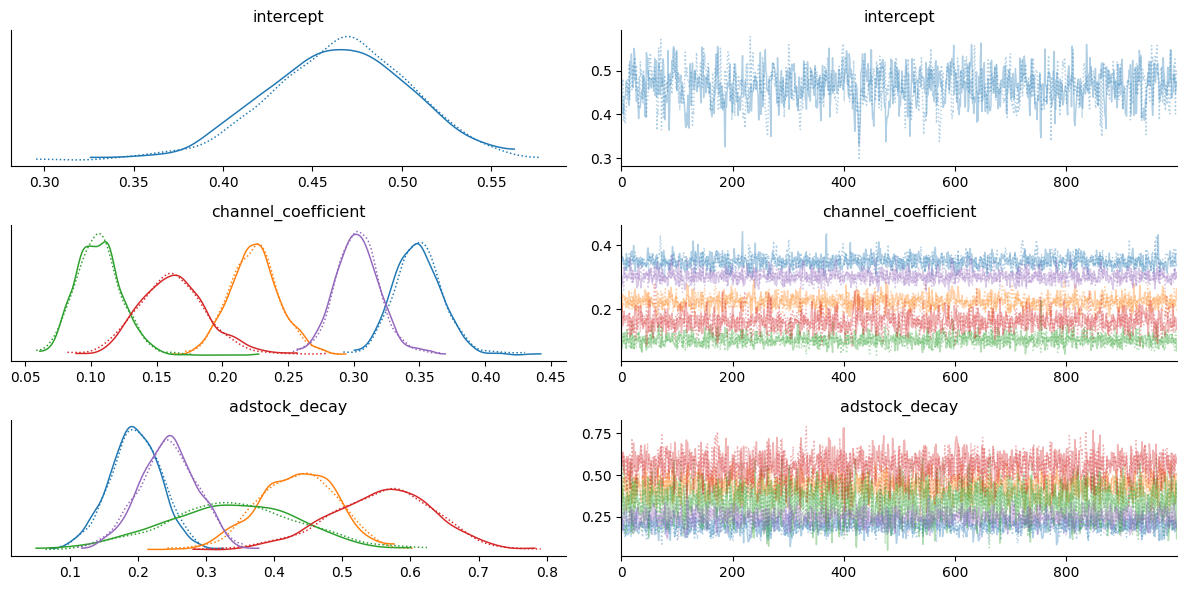

In [10]:
parameter_names = ['intercept', 'channel_coefficient', 'adstock_decay',
                   'half_saturation', 'control_coefficient', 'sigma']
diagnostics = az.summary(idata, var_names=parameter_names, round_to=4)
display(diagnostics)
max_rhat = diagnostics['r_hat'].max()
min_bulk_ess = diagnostics['ess_bulk'].min()
min_tail_ess = diagnostics['ess_tail'].min()
divergences = int(idata.sample_stats['diverging'].sum())
bfmi = az.bfmi(idata)
print(f'Max R-hat: {max_rhat:.4f}')
print(f'Min bulk ESS: {min_bulk_ess:.1f}; min tail ESS: {min_tail_ess:.1f}')
print('Divergences:', divergences)
print('BFMI by chain:', bfmi)
assert max_rhat < 1.01, 'Inspect mixing before interpreting this model.'
assert min_bulk_ess > 400 and min_tail_ess > 400
assert divergences == 0
assert np.all(bfmi > 0.3)

az.plot_trace(idata, var_names=['intercept', 'channel_coefficient', 'adstock_decay'], compact=True)
plt.tight_layout()
plt.show()

## 8. Model fit

The shaded band is a 94% posterior **predictive** interval, including observation noise. The fitted line
is the posterior mean expected GMV. MAE and RMSE below are in-sample checks, not evidence of forecasting
accuracy. A time-based holdout and prior sensitivity analysis would be needed before business use.

Sampling: [observed_gmv]


C:\Users\chint\Documents\Codex\2026-10-01\i-want-you-to-build-a\work\mmm-env\Lib\site-packages\rich\live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

In-sample MAE: 5,145.08 CU; RMSE: 6,439.91 CU
In-sample 94% predictive interval coverage: 96.2%


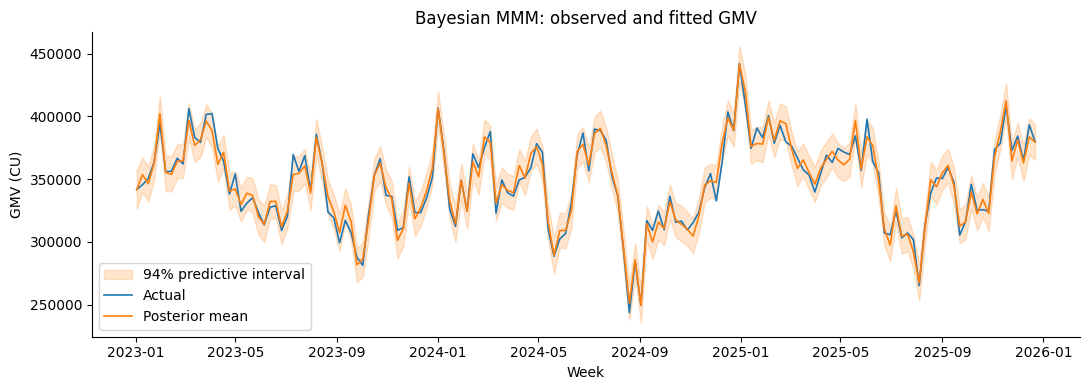

In [11]:
with mmm:
    posterior_predictive = pm.sample_posterior_predictive(
        idata, var_names=['observed_gmv'], random_seed=random_seed)

predicted_gmv = idata.posterior['expected_gmv'].mean(dim=('chain', 'draw')).to_numpy() * gmv_scale
predictive_draws = posterior_predictive.posterior_predictive['observed_gmv'].to_numpy().reshape(-1, len(marketing_data)) * gmv_scale
lower_gmv, upper_gmv = np.quantile(predictive_draws, [0.03, 0.97], axis=0)
actual_gmv = marketing_data['gmv'].to_numpy()
mae = np.mean(np.abs(actual_gmv - predicted_gmv))
rmse = np.sqrt(np.mean((actual_gmv - predicted_gmv) ** 2))
coverage = np.mean((actual_gmv >= lower_gmv) & (actual_gmv <= upper_gmv))
print(f'In-sample MAE: {mae:,.2f} CU; RMSE: {rmse:,.2f} CU')
print(f'In-sample 94% predictive interval coverage: {coverage:.1%}')

plt.fill_between(marketing_data['date'], lower_gmv, upper_gmv, alpha=0.2,
                 color='tab:orange', label='94% predictive interval')
plt.plot(marketing_data['date'], actual_gmv, label='Actual', linewidth=1.2)
plt.plot(marketing_data['date'], predicted_gmv, label='Posterior mean', linewidth=1.2)
plt.xlabel('Week')
plt.ylabel('GMV (CU)')
plt.title('Bayesian MMM: observed and fitted GMV')
plt.legend()
plt.tight_layout()
plt.savefig(output_folder / 'model_fit.png', dpi=160)
plt.show()

## 9. Channel contributions

For an easy-to-explain decomposition I plug posterior mean parameters into the transformations.
Because the model is nonlinear, these plug-in contributions differ slightly from averaging contributions
over every posterior draw. Contribution percentage uses total **observed GMV** as its denominator, so media
shares need not sum to 100%. `estimated_roi` means attributed GMV / spend (revenue ROAS), not profit ROI.

Calculating channel contributions...


,channel,total_spend,estimated_gmv_contribution,contribution_pct,estimated_roi
0,Paid search,"4,100,944.26","8,503,045.94",15.70,2.07
1,Social,"3,607,922.55","6,004,181.69",11.09,1.66
2,Display,"2,832,329.21","2,855,433.80",5.27,1.01
3,Video,"2,943,731.45","4,354,323.66",8.04,1.48
4,Affiliate,"1,402,410.12","6,549,875.80",12.09,4.67


Media total: 28,266,860.88 CU
Baseline plus controls: 25,150,545.00 CU
Observed minus plug-in fitted total: 736,212.86 CU


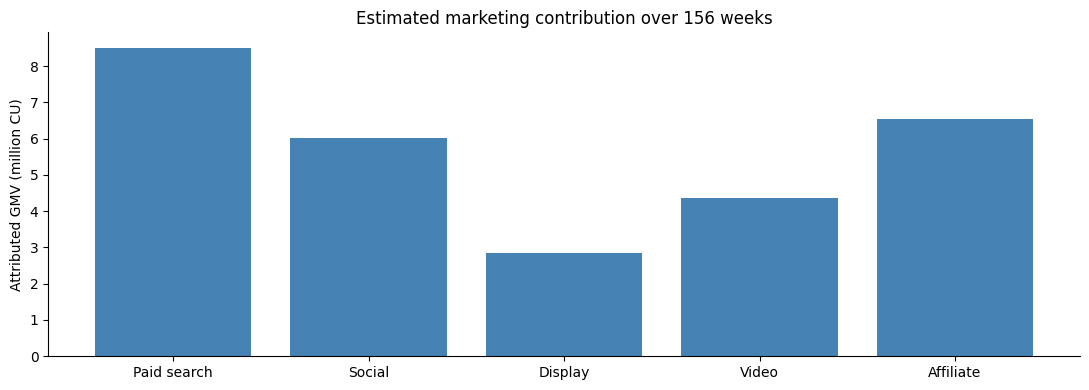

In [12]:
print('Calculating channel contributions...')
posterior_means = idata.posterior.mean(dim=('chain', 'draw'))
decay_estimate = posterior_means['adstock_decay'].to_numpy()
saturation_estimate = posterior_means['half_saturation'].to_numpy()
coefficient_estimate = posterior_means['channel_coefficient'].to_numpy()
control_estimate = posterior_means['control_coefficient'].to_numpy()
intercept_estimate = float(posterior_means['intercept'])

weekly_contribution = np.zeros_like(scaled_spend)
for j, channel in enumerate(channel_columns):
    adstocked_spend = geometric_adstock(scaled_spend[:, j], decay_estimate[j], max_lag)
    weekly_contribution[:, j] = (coefficient_estimate[j]
        * hill_saturation(adstocked_spend, saturation_estimate[j]) * gmv_scale)

total_gmv = marketing_data['gmv'].sum()
channel_contribution = pd.DataFrame({
    'channel': channel_names,
    'total_spend': marketing_data[channel_columns].sum().to_numpy(),
    'estimated_gmv_contribution': weekly_contribution.sum(axis=0)})
channel_contribution['contribution_pct'] = channel_contribution['estimated_gmv_contribution'] / total_gmv * 100
channel_contribution['estimated_roi'] = channel_contribution['estimated_gmv_contribution'] / channel_contribution['total_spend']
display(channel_contribution)

baseline_and_controls = (intercept_estimate + scaled_controls @ control_estimate) * gmv_scale
plug_in_gmv = baseline_and_controls + weekly_contribution.sum(axis=1)
print(f'Media total: {weekly_contribution.sum():,.2f} CU')
print(f'Baseline plus controls: {baseline_and_controls.sum():,.2f} CU')
print(f'Observed minus plug-in fitted total: {total_gmv - plug_in_gmv.sum():,.2f} CU')

plt.bar(channel_names, channel_contribution['estimated_gmv_contribution'] / 1e6, color='steelblue')
plt.ylabel('Attributed GMV (million CU)')
plt.title('Estimated marketing contribution over 156 weeks')
plt.tight_layout()
plt.savefig(output_folder / 'channel_contributions.png', dpi=160)
plt.show()

## 10. Current budget and response curves

Current spending is the average weekly spend over the dataset. For planning I hold all centered controls
at zero, representing average historical conditions, and assume a constant budget sustained for at least
eight weeks. Normalized adstock of constant spend equals that spend after the lag window fills. Carryover
therefore matters for the fitted history and transition period, but cancels from these steady-state curves.

Current projected GMV need not equal historical average GMV: a nonlinear response to constant average
spend differs from the average response to changing weekly spend.

These are conditional planning scenarios, not a forecast for the next calendar week. The curves show
each channel's contribution; their heights are not total GMV. Shading gives a 94% parameter uncertainty band.

,channel,current_weekly_spend,current_share
0,Paid search,"26,288.10",0.28
1,Social,"23,127.71",0.24
2,Display,"18,155.96",0.19
3,Video,"18,870.07",0.20
4,Affiliate,"8,989.81",0.09


Current total weekly marketing budget: 95,431.65 CU


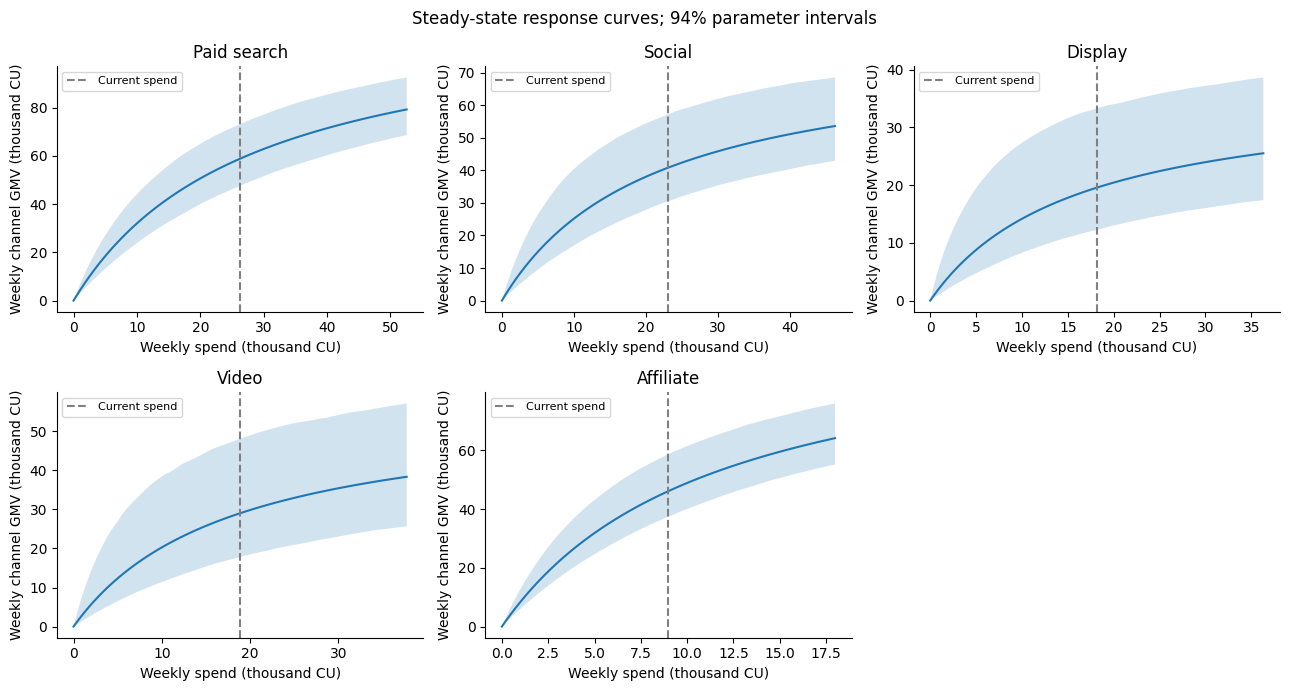

,channel,marginal_gmv_per_cu,slope_remaining_vs_zero_pct
0,Paid search,1.15,26.53
1,Social,0.84,22.61
2,Display,0.50,21.80
3,Video,0.75,23.67
4,Affiliate,2.88,31.57


In [13]:
current_spend = marketing_data[channel_columns].mean().to_numpy()
current_budget = current_spend.sum()
current_budget_table = pd.DataFrame({'channel': channel_names,
                                     'current_weekly_spend': current_spend,
                                     'current_share': current_spend / current_budget})
display(current_budget_table)
print(f'Current total weekly marketing budget: {current_budget:,.2f} CU')

def predict_channel_response(spend, channel_index):
    scaled_value = np.asarray(spend) / spend_scale[channel_index]
    return (coefficient_estimate[channel_index]
            * hill_saturation(scaled_value, saturation_estimate[channel_index]) * gmv_scale)

def predict_gmv(spend):
    channel_gmv = 0.0
    for j in range(len(channel_columns)):
        channel_gmv += predict_channel_response(spend[j], j)
    return intercept_estimate * gmv_scale + channel_gmv

posterior_samples = idata.posterior.stack(sample=('chain', 'draw'))
coefficient_draws = posterior_samples['channel_coefficient'].transpose('sample', 'channel').to_numpy()
saturation_draws = posterior_samples['half_saturation'].transpose('sample', 'channel').to_numpy()
intercept_draws = posterior_samples['intercept'].to_numpy()

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for j, ax in enumerate(axes.flat[:5]):
    spend_grid = np.linspace(0, 2 * current_spend[j], 100)
    response = predict_channel_response(spend_grid, j)
    response_draws = (coefficient_draws[:, j, None] * gmv_scale
        * hill_saturation(spend_grid[None, :] / spend_scale[j], saturation_draws[:, j, None]))
    low, high = np.quantile(response_draws, [0.03, 0.97], axis=0)
    ax.fill_between(spend_grid / 1000, low / 1000, high / 1000, alpha=0.2)
    ax.plot(spend_grid / 1000, response / 1000)
    ax.axvline(current_spend[j] / 1000, color='gray', linestyle='--', label='Current spend')
    ax.set(title=channel_names[j], xlabel='Weekly spend (thousand CU)',
           ylabel='Weekly channel GMV (thousand CU)')
    ax.legend(fontsize=8)
    assert np.all(np.diff(response) >= 0)
    assert np.all(np.diff(response, n=2) <= 1e-7)
axes.flat[-1].axis('off')
fig.suptitle('Steady-state response curves; 94% parameter intervals')
fig.tight_layout()
fig.savefig(output_folder / 'response_curves.png', dpi=160)
plt.show()

# Compare marginal return at current spend with the slope close to zero.
marginal_return = (gmv_scale * coefficient_estimate * saturation_estimate
                  / (spend_scale * (saturation_estimate + current_spend / spend_scale) ** 2))
initial_return = gmv_scale * coefficient_estimate / (spend_scale * saturation_estimate)
slope_remaining_pct = marginal_return / initial_return * 100
display(pd.DataFrame({'channel': channel_names, 'marginal_gmv_per_cu': marginal_return,
                      'slope_remaining_vs_zero_pct': slope_remaining_pct}))

## 11. Fixed-budget reallocation

SLSQP maximizes projected GMV while total spending stays unchanged. Each channel must stay between
30% and 180% of current spending. These are illustrative operational bounds to avoid recommending a
complete shutdown or an untested large expansion. I optimize spend **multipliers** and scale the objective
and constraints so the solver handles values around one rather than large currency amounts.

In [14]:
print('Running budget optimization...')
predicted_gmv_before = predict_gmv(current_spend)
bounds = [(0.30, 1.80)] * len(channel_columns)
fixed_budget_result = minimize(
    lambda spend_multiplier: -predict_gmv(spend_multiplier * current_spend) / gmv_scale,
    x0=np.ones(len(channel_columns)), method='SLSQP', bounds=bounds,
    constraints=[{'type': 'eq', 'fun': lambda spend_multiplier:
                  np.sum(spend_multiplier * current_spend) / current_budget - 1}],
    options={'ftol': 1e-12, 'maxiter': 1000})

print('Fixed-budget solver:', fixed_budget_result.success, fixed_budget_result.message)
assert fixed_budget_result.success, fixed_budget_result.message
fixed_budget_spend = fixed_budget_result.x * current_spend
fixed_budget_gmv = predict_gmv(fixed_budget_spend)
fixed_budget_error = abs(fixed_budget_spend.sum() - current_budget)
assert fixed_budget_error < 0.01
assert np.all(fixed_budget_result.x >= 0.30 - 1e-8)
assert np.all(fixed_budget_result.x <= 1.80 + 1e-8)
assert fixed_budget_gmv >= predicted_gmv_before - 0.01
fixed_budget_improvement_pct = (fixed_budget_gmv / predicted_gmv_before - 1) * 100
display(pd.DataFrame({'channel': channel_names, 'current_spend': current_spend,
                      'fixed_budget_spend': fixed_budget_spend,
                      'change_pct': (fixed_budget_spend / current_spend - 1) * 100}))
print(f'Budget equality error: {fixed_budget_error:.10f} CU')
print(f'Projected GMV: {predicted_gmv_before:,.2f} -> {fixed_budget_gmv:,.2f} CU')
print(f'Fixed-budget projected improvement: {fixed_budget_improvement_pct:.2f}%')

Running budget optimization...
Fixed-budget solver: True Optimization terminated successfully


,channel,current_spend,fixed_budget_spend,change_pct
0,Paid search,"26,288.10","33,056.33",25.75
1,Social,"23,127.71","21,371.61",-7.59
2,Display,"18,155.96","9,407.04",-48.19
3,Video,"18,870.07","15,415.03",-18.31
4,Affiliate,"8,989.81","16,181.66",80.00


Budget equality error: 0.0000000143 CU
Projected GMV: 355,636.18 -> 367,606.58 CU
Fixed-budget projected improvement: 3.37%


## 12. Minimum budget at a GMV target

The performance threshold is set at **97% of current projected total GMV** before optimization. It is a
business scenario assumption, not a target reduction in spending. Baseline demand is included, so retaining
97% of total GMV does not mean retaining 97% of media-attributed GMV. The objective now minimizes spend,
using the same channel bounds. A tiny numerical margin keeps the verified solution above the stated target.

In [15]:
retention_target = 0.97
target_gmv = retention_target * predicted_gmv_before
solver_target_gmv = target_gmv + 0.01
minimum_budget_result = minimize(
    lambda spend_multiplier: np.sum(spend_multiplier * current_spend) / current_budget,
    x0=fixed_budget_result.x, method='SLSQP', bounds=bounds,
    constraints=[{'type': 'ineq', 'fun': lambda spend_multiplier:
                  (predict_gmv(spend_multiplier * current_spend) - solver_target_gmv) / gmv_scale}],
    options={'ftol': 1e-12, 'maxiter': 1000})

print('Minimum-budget solver:', minimum_budget_result.success, minimum_budget_result.message)
assert minimum_budget_result.success, minimum_budget_result.message
optimized_spend = minimum_budget_result.x * current_spend
budget_before = current_budget
budget_after = optimized_spend.sum()
predicted_gmv_after = predict_gmv(optimized_spend)
budget_reduction_pct = (1 - budget_after / budget_before) * 100
gmv_change_pct = (predicted_gmv_after / predicted_gmv_before - 1) * 100
target_slack = predicted_gmv_after - target_gmv
assert predicted_gmv_after >= target_gmv
assert budget_after <= budget_before + 0.01
assert np.all(minimum_budget_result.x >= 0.30 - 1e-8)
assert np.all(minimum_budget_result.x <= 1.80 + 1e-8)

scenario_results = pd.DataFrame({
    'scenario': ['Current', 'Fixed-budget reallocation', 'Minimum budget'],
    'weekly_budget': [budget_before, fixed_budget_spend.sum(), budget_after],
    'projected_weekly_gmv': [predicted_gmv_before, fixed_budget_gmv, predicted_gmv_after],
    'budget_reduction_pct': [0, 0, budget_reduction_pct],
    'gmv_change_pct': [0, fixed_budget_improvement_pct, gmv_change_pct]})
display(scenario_results)
print(f'Target GMV: {target_gmv:,.2f} CU; constraint slack: {target_slack:.8f} CU')
print(f'Actual budget reduction: {budget_reduction_pct:.2f}%')

Minimum-budget solver: True Optimization terminated successfully


,scenario,weekly_budget,projected_weekly_gmv,budget_reduction_pct,gmv_change_pct
0,Current,"95,431.65","355,636.18",0.00,0.00
1,Fixed-budget reallocation,"95,431.65","367,606.58",0.00,3.37
2,Minimum budget,"73,895.08","344,967.10",22.57,-3.00


Target GMV: 344,967.09 CU; constraint slack: 0.01000000 CU
Actual budget reduction: 22.57%


## 13. Compare budgets and check uncertainty

The optimizer uses posterior mean parameters. To show what this leaves out, I evaluate the chosen minimum
budget under every posterior draw, comparing against the same draw's current GMV. This is a parameter
uncertainty check, not a probability of realized sales: it excludes future observation noise and model error.
The optimized constraint is a point-estimate constraint, not a guarantee across the posterior.

,channel,current_spend,fixed_budget_spend,optimized_spend,difference,change_pct
0,Paid search,"26,288.10","33,056.33","24,946.01","-1,342.10",-5.11
1,Social,"23,127.71","21,371.61","15,740.29","-7,387.42",-31.94
2,Display,"18,155.96","9,407.04","6,040.71","-12,115.24",-66.73
3,Video,"18,870.07","15,415.03","10,986.41","-7,883.66",-41.78
4,Affiliate,"8,989.81","16,181.66","16,181.66","7,191.85",80.00


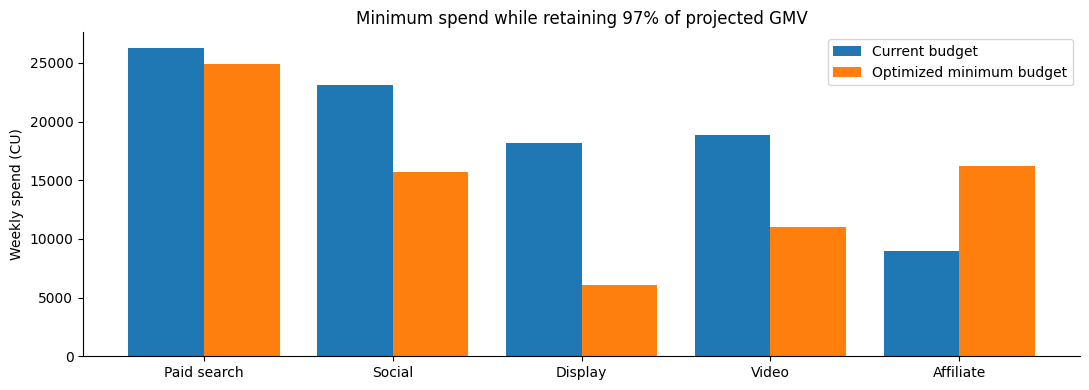

94% parameter interval for GMV retained: 96.17% to 98.23%
Posterior draws meeting the 97% relative target: 65.1%


In [16]:
optimized_budget = pd.DataFrame({'channel': channel_names,
    'current_spend': current_spend, 'fixed_budget_spend': fixed_budget_spend,
    'optimized_spend': optimized_spend})
optimized_budget['difference'] = optimized_spend - current_spend
optimized_budget['change_pct'] = (optimized_spend / current_spend - 1) * 100
display(optimized_budget)
optimized_budget.to_csv(output_folder / 'optimized_budget.csv', index=False)

x = np.arange(len(channel_names))
plt.bar(x - 0.2, current_spend, width=0.4, label='Current budget')
plt.bar(x + 0.2, optimized_spend, width=0.4, label='Optimized minimum budget')
plt.xticks(x, channel_names)
plt.ylabel('Weekly spend (CU)')
plt.title('Minimum spend while retaining 97% of projected GMV')
plt.legend()
plt.tight_layout()
plt.show()

current_gmv_draws = (intercept_draws + (coefficient_draws
    * hill_saturation(current_spend / spend_scale, saturation_draws)).sum(axis=1)) * gmv_scale
optimized_gmv_draws = (intercept_draws + (coefficient_draws
    * hill_saturation(optimized_spend / spend_scale, saturation_draws)).sum(axis=1)) * gmv_scale
posterior_retention = optimized_gmv_draws / current_gmv_draws
retention_interval = np.quantile(posterior_retention, [0.03, 0.97])
posterior_target_fraction = np.mean(optimized_gmv_draws >= retention_target * current_gmv_draws)
print(f'94% parameter interval for GMV retained: {retention_interval[0]:.2%} to {retention_interval[1]:.2%}')
print(f'Posterior draws meeting the 97% relative target: {posterior_target_fraction:.1%}')

## Final Results

In [17]:
most_productive = channel_contribution.sort_values('estimated_roi', ascending=False)['channel'].iloc[0]
strongest_saturation = channel_names[int(np.argmin(slope_remaining_pct))]
largest_cut = channel_names[int(np.argmin(optimized_spend - current_spend))]
largest_increase = channel_names[int(np.argmax(fixed_budget_spend - current_spend))]
display(Markdown(f"""
- **{most_productive}** has the highest estimated historical GMV per unit of spend.
- **{strongest_saturation}** has the greatest relative slope loss at current spend versus near-zero spend.
- Fixed-budget SLSQP adds the most spending to **{largest_increase}** and raises projected weekly GMV
  from **{predicted_gmv_before:,.2f}** to **{fixed_budget_gmv:,.2f} CU** (**{fixed_budget_improvement_pct:.2f}%**).
- Minimum-budget SLSQP makes its largest absolute cut in **{largest_cut}**. Weekly spending falls from
  **{budget_before:,.2f}** to **{budget_after:,.2f} CU**, a **{budget_reduction_pct:.2f}% reduction**.
- Projected weekly GMV becomes **{predicted_gmv_after:,.2f} CU** (**{gmv_change_pct:.2f}%**), meeting
  the **{target_gmv:,.2f} CU** target. Both optimizers report success and pass numerical constraint checks.
- Max R-hat is **{max_rhat:.4f}**, minimum bulk ESS **{min_bulk_ess:.0f}**, minimum tail ESS
  **{min_tail_ess:.0f}**, and divergences **{divergences}**.
- Only **{posterior_target_fraction:.1%}** of posterior draws meet the relative GMV target for this budget;
  the point-estimate optimum does not provide a high-confidence performance guarantee.

The dataset is synthetic. This project demonstrates methodology rather than making a real company's
marketing recommendation. MMM estimates statistical attribution, not causality. Response curves depend
on priors, the fixed concave Hill shape and additive channel assumptions. Fit metrics are in-sample;
there is no time-based validation or prior sensitivity study here. Optimization assumes steady-state
spend and average historical controls, omits transition effects, and optimizes GMV rather than profit.
"""))


- **Affiliate** has the highest estimated historical GMV per unit of spend.
- **Display** has the greatest relative slope loss at current spend versus near-zero spend.
- Fixed-budget SLSQP adds the most spending to **Affiliate** and raises projected weekly GMV
  from **355,636.18** to **367,606.58 CU** (**3.37%**).
- Minimum-budget SLSQP makes its largest absolute cut in **Display**. Weekly spending falls from
  **95,431.65** to **73,895.08 CU**, a **22.57% reduction**.
- Projected weekly GMV becomes **344,967.10 CU** (**-3.00%**), meeting
  the **344,967.09 CU** target. Both optimizers report success and pass numerical constraint checks.
- Max R-hat is **1.0033**, minimum bulk ESS **749**, minimum tail ESS
  **880**, and divergences **0**.
- Only **65.1%** of posterior draws meet the relative GMV target for this budget;
  the point-estimate optimum does not provide a high-confidence performance guarantee.

The dataset is synthetic. This project demonstrates methodology rather than making a real company's
marketing recommendation. MMM estimates statistical attribution, not causality. Response curves depend
on priors, the fixed concave Hill shape and additive channel assumptions. Fit metrics are in-sample;
there is no time-based validation or prior sensitivity study here. Optimization assumes steady-state
spend and average historical controls, omits transition effects, and optimizes GMV rather than profit.
